# 06. 学習済み方策のシミュレーションでの動作確認

05の学習済みモデル（学習用PCで150エポック学習したDP・ACTの最良モデル）を、MuJoCoのシミュレーション上のSO-101で実際に動かす。
方策への画像入力は、SO-101の手首カメラ`wrist_cam`で撮影したシミュレーション画像である。

**確認すること**

| パターン | SO-101の見た目と手首カメラ |
|---|---|
| 1. 素のモデル | mujoco_menagerieの`so101.xml`のまま（黄色の外装、手首カメラも元の向き） |
| 2. Grabetteに似せたモデル | グリッパーをGrabetteの外観（白いフレーム・黒いゴムパッド・黒いカメラ部）に塗り分け、手首カメラをグリッパーの先の方向に向けたもの |

缶は、実演で掴んでいる缶と同じ形のものを、03の縮小率に合わせた大きさで作り、学習データで掴んでいる位置に置く。

**結論の先取り**: どちらのパターンでも、DP・ACTとも缶を持ち上げることはできない。
その理由を、実験と01〜05の内容から考察する（7節）。

In [1]:
# ============================================================
# パス設定
# ============================================================
# このノートブックはfor_submit/ディレクトリで実行することを前提とする。
# 以降のすべてのパスはfor_submit/を起点とした相対位置で定義する。
from pathlib import Path

ROOT = Path.cwd()                      # for_submit/ディレクトリ
DATA_DIR = ROOT / "data"               # 外部から取得したデータの置き場所
OUT_DIR = ROOT / "outputs"             # このノートブックで作成する図・動画の置き場所

# Grabetteデータセット（HuggingFaceから取得）の保存先
GRABETTE_DIR = DATA_DIR / "grabette_pick3_cartesian_480"

# SO-101のMuJoCoモデル（mujoco_menagerieから取得）の保存先
MENAGERIE_DIR = DATA_DIR / "mujoco_menagerie"
MJCF_PATH = MENAGERIE_DIR / "robotstudio_so101" / "so101.xml"
# 描画用のシーン（so101.xmlに床・照明・背景を足したもの。同じmujoco_menagerieに含まれる）
SCENE_PATH = MENAGERIE_DIR / "robotstudio_so101" / "scene.xml"

OUT_DIR.mkdir(parents=True, exist_ok=True)
# print("ROOT         :", ROOT)
# print("GRABETTE_DIR :", GRABETTE_DIR)
# print("MJCF_PATH    :", MJCF_PATH)

In [2]:
# ============================================================
# 図のスタイル設定
# ============================================================
# 系列の色は固定順で割り当てる（1:青, 2:橙, 3:緑青, 4:黄, 5:桃, 6:緑, 7:紫, 8:赤）。
# 成功/失敗などの「状態」には、系列色とは別に専用の2色を使う。
import matplotlib.pyplot as plt
import japanize_matplotlib  # noqa: F401  （図中の日本語表示に必要）

SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                 "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLOR_GOOD = "#0ca30c"      # 成功・採用を表す色
COLOR_BAD = "#d03b3b"       # 失敗・除外を表す色
COLOR_MUTED = "#898781"     # 補助線・参考情報の色

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2.0,
    "legend.frameon": False,
})

In [3]:
# ============================================================
# 動画の保存とノートブックへの埋め込み
# ============================================================
# 動画はoutputs/にmp4として保存し、さらにbase64文字列として
# ノートブックに直接埋め込む。こうすることで、ノートブック単体を
# 開いただけで動画を再生できる。
import base64

import imageio
from IPython.display import HTML, display


def save_mp4(frames, path, fps=10):
    """RGB画像（H, W, 3）のリストをmp4ファイルとして保存する。"""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    imageio.mimwrite(str(path), frames, fps=fps, macro_block_size=1)
    return path


def show_mp4(path, width=720, title=""):
    """mp4ファイルをbase64で埋め込み、ノートブック上で再生できるようにする。"""
    data = base64.b64encode(Path(path).read_bytes()).decode()
    header = f"<p style='font-family:monospace;margin:4px 0'>{title}</p>"
    video = (f"<video width='{width}' controls loop muted>"
             f"<source src='data:video/mp4;base64,{data}' type='video/mp4'>"
             "</video>")
    display(HTML(header + video))

In [4]:
# ============================================================
# 使うファイル
# ============================================================
import json
import xml.etree.ElementTree as ET

import av
import cv2
import mujoco
import numpy as np
import pandas as pd
import torch

DP_DIR = ROOT / "training_results" / "dp" / "best"     # 05のDP最良モデル
ACT_DIR = ROOT / "training_results" / "act" / "best"   # 05のACT最良モデル
DATASET_ACT = OUT_DIR / "so101_lerobot_dataset"            # 04基本版
DATASET_DP = OUT_DIR / "so101_lerobot_dataset_wristcam"    # 04手首カメラ選別版
SIM_DIR = OUT_DIR / "06_sim"
SIM_DIR.mkdir(parents=True, exist_ok=True)

JOINT_NAMES = ["shoulder_pan", "shoulder_lift", "elbow_flex",
               "wrist_flex", "wrist_roll", "gripper"]
DATASET_FPS = 30       # 04で記録したfps。1ステップ = データの1フレーム
GRABETTE_EP = 10       # 01〜05で代表例にしたエピソード

mapping = pd.read_csv(OUT_DIR / "04_episode_mapping.csv")
row = mapping[mapping["grabette_episode"] == GRABETTE_EP].iloc[0]
EP_ACT = int(row["dataset_episode"])             # 基本版の中での番号
EP_DP = int(row["dataset_episode_wristcam"])     # 手首カメラ選別版の中での番号
print(f"Grabetteエピソード{GRABETTE_EP} → 基本版{EP_ACT} / 手首カメラ選別版{EP_DP}")


def load_episode(dataset_dir, episode):
    """データセットから1エピソードの関節角(T, 6)と画像(T, H, W, 3)を読む。"""
    frames = pd.read_parquet(dataset_dir / "data" / "chunk-000"
                             / "file-000.parquet")
    joints = np.stack(frames.loc[frames["episode_index"] == episode,
                                 "action"].to_numpy()).astype(float)
    video = (dataset_dir / "videos" / "observation.image" / "chunk-000"
             / f"file-{episode:03d}.mp4")
    with av.open(str(video)) as container:
        images = np.stack([f.to_ndarray(format="rgb24")
                           for f in container.decode(video=0)])
    return joints, images


demo_joints, demo_images = load_episode(DATASET_ACT, EP_ACT)
demo_joints_dp, demo_images_dp = load_episode(DATASET_DP, EP_DP)
# 2つのデータセットの同じエピソードは、同じ関節角・同じ画像である（04の5.4節）
assert np.array_equal(demo_joints, demo_joints_dp)
print(f"学習データのエピソード: {len(demo_joints)}フレーム, 画像{demo_images.shape[1:]}")

Grabetteエピソード10 → 基本版6 / 手首カメラ選別版6


学習データのエピソード: 142フレーム, 画像(160, 160, 3)


## 1. 評価環境を作る

### 1.1 缶の大きさ

実演で掴んでいる缶は330 mlの飲料缶（直径約66 mm、高さ約115 mm）である（01の映像）。
03では、人の手の動きを **0.75倍** に縮めてSO-101の動作にした。
そのため、手と物体の大きさの関係を実演と揃えるには、缶も同じ0.75倍にする必要がある。
そこで缶は、直径49.5 mm、高さ86.3 mmの円柱とする。
この直径は、SO-101のグリッパーの全開時の間隔（約133 mm）より小さく、全閉時の間隔（約16 mm, 02）より大きい。
つまり、開いて挟み込み、閉じて保持できる大きさである。
質量は50 gとした（※裏で試行錯誤して、この値に決定した）。

### 1.2 缶の置き場所

缶は、学習データのエピソード10で **グリッパーが最も閉じた時刻** の先端（`gripperframe`）の位置に、缶の中心が来るように置く。
テーブルの上面は缶の底の高さとする。
こうすると、学習データの動作どおりに腕を動かせば、ちょうど缶を挟む位置でグリッパーが閉じる。

グリッパーが最も閉じた時刻: フレーム37
缶の中心[m]: [0.279 0.009 0.062], テーブル上面の高さ: 0.019 m
先端がテーブル上面より下に入るフレーム: 0 / 142
ジョーの部品の下端がテーブル上面より下になるフレーム（概算）: 41 / 142


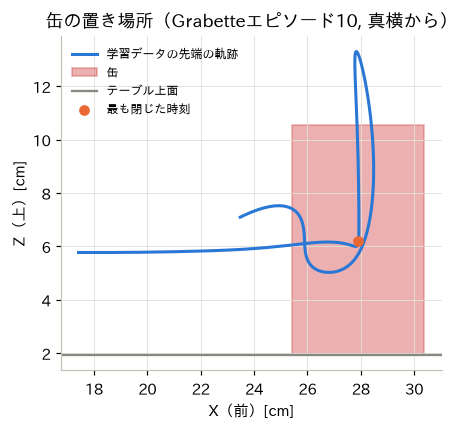

In [5]:
SCALE = 0.75                         # 03の縮小率
CAN_RADIUS = 0.033 * SCALE           # 330 ml缶の半径33 mm × 0.75
CAN_HEIGHT = 0.115 * SCALE           # 330 ml缶の高さ115 mm × 0.75
CAN_MASS = 0.05                      # [kg]

robot_model = mujoco.MjModel.from_xml_path(str(MJCF_PATH))
robot_data = mujoco.MjData(robot_model)
EE_SITE = mujoco.mj_name2id(robot_model, mujoco.mjtObj.mjOBJ_SITE,
                            "gripperframe")


def tip_positions(joints):
    """関節角の時系列(T, 6)から、先端（gripperframe）の位置(T, 3)をFKで求める。"""
    positions = []
    for q in joints:
        robot_data.qpos[:6] = q
        mujoco.mj_forward(robot_model, robot_data)
        positions.append(robot_data.site_xpos[EE_SITE].copy())
    return np.array(positions)


demo_tips = tip_positions(demo_joints)
grasp_t = int(demo_joints[:, 5].argmin())          # グリッパーが最も閉じた時刻
window = slice(max(0, grasp_t - 3), grasp_t + 4)   # 前後3フレームで平均
CAN_CENTER = demo_tips[window].mean(axis=0)
TABLE_Z = CAN_CENTER[2] - CAN_HEIGHT / 2           # テーブル上面 = 缶の底
print(f"グリッパーが最も閉じた時刻: フレーム{grasp_t}")
print(f"缶の中心[m]: {np.round(CAN_CENTER, 3)}, テーブル上面の高さ: {TABLE_Z:.3f} m")
below = demo_tips[:, 2] < TABLE_Z
print(f"先端がテーブル上面より下に入るフレーム: {below.sum()} / {len(below)}")

# ジョーの部品（接触判定に使う形状）の下端の高さを、各形状を囲む球で概算する
jaw_bodies = {mujoco.mj_name2id(robot_model, mujoco.mjtObj.mjOBJ_BODY, name)
              for name in ("gripper", "moving_jaw_so101_v1")}
jaw_geoms = [g for g in range(robot_model.ngeom)
             if robot_model.geom_bodyid[g] in jaw_bodies
             and robot_model.geom_contype[g]]
lowest = []
for q in demo_joints:
    robot_data.qpos[:6] = q
    mujoco.mj_forward(robot_model, robot_data)
    lowest.append(min(robot_data.geom_xpos[g][2] - robot_model.geom_rbound[g]
                      for g in jaw_geoms))
lowest = np.array(lowest)
print(f"ジョーの部品の下端がテーブル上面より下になるフレーム（概算）: "
      f"{(lowest < TABLE_Z).sum()} / {len(lowest)}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(demo_tips[:, 0] * 100, demo_tips[:, 2] * 100, color=SERIES_COLORS[0],
        label="学習データの先端の軌跡")
ax.add_patch(plt.Rectangle(((CAN_CENTER[0] - CAN_RADIUS) * 100, TABLE_Z * 100),
                           CAN_RADIUS * 200, CAN_HEIGHT * 100,
                           color=COLOR_BAD, alpha=0.4, label="缶"))
ax.axhline(TABLE_Z * 100, color=COLOR_MUTED, lw=1.5, label="テーブル上面")
ax.scatter(demo_tips[grasp_t, 0] * 100, demo_tips[grasp_t, 2] * 100,
           color=SERIES_COLORS[1], zorder=3, label="最も閉じた時刻")
ax.set_aspect("equal")
ax.set_xlabel("X（前）[cm]")
ax.set_ylabel("Z（上）[cm]")
ax.set_title(f"缶の置き場所（Grabetteエピソード{GRABETTE_EP}, 真横から）")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(OUT_DIR / "06_can_placement.png", bbox_inches="tight")
plt.show()

### 1.3 2つのパターンのモデルを作る

どちらのパターンにも、テーブル・缶・照明を加える。
缶は重力と接触力で動く自由な物体である。
グリッパーとテーブルの接触は計算しない。
先端（`gripperframe`）はテーブル上面より下に入らないが、ジョーの部品は先端より下に張り出している。
そのため、缶を掴む高さではジョーの部品がテーブル面に触れ、めり込むことがある（1.2節のセルの概算では142フレーム中41フレーム）。
腕は目標の関節角へ直接動かす（1.4節）ため、めり込んだジョーが缶やテーブルを弾き飛ばすのを避ける目的である。

パターン2の外観の変更は、本プロジェクトでGrabetteの見た目に合わせて作った設定を移植したものである。

| 変更点 | 内容 |
|---|---|
| グリッパーのフレーム | 白（Grabetteの白い樹脂部品） |
| ジョーの内側 | 黒いゴムパッド（厚さ3 mm） |
| 手首カメラの取り付け部 | 黒 |
| 手首カメラの向き・視野 | `euler="0 0 0"`（グリッパーの先の方向）、視野角90度（04の3.2節と同じ） |
| 照明 | 白いフレームが暗く見えないよう、全体の明るさを上げる |

In [6]:
WHITE = "0.90 0.90 0.90 1"
BLACK = "0.08 0.08 0.08 1"


def make_grabette_like(root):
    """グリッパーをGrabetteの外観に塗り分け、手首カメラを前に向ける。"""
    asset = root.find("asset")
    black = ET.SubElement(asset, "material")
    black.set("name", "grabette_black")
    black.set("rgba", BLACK)
    # MuJoCoは形状（mesh）に「形状名_material」という材質を自動で使うため、
    # 部品の色は材質（material）の側で変える
    for material in asset.iter("material"):
        if material.get("name") in ("wrist_roll_follower_so101_v1_material",
                                    "moving_jaw_so101_v1_material"):
            material.set("rgba", WHITE)
            material.set("emission", "0.25")    # 少し自ら光らせ、白く見せる
            material.set("specular", "0.5")
            material.set("shininess", "0.3")
    for geom in root.iter("geom"):
        # カメラ取り付け部は、白いフレームと同じ材質を使っているので個別に黒にする
        if geom.get("mesh") == "wrist_roll_follower_so101_camera_mount":
            geom.set("material", "grabette_black")
    # ジョーの内側に、見た目だけの黒いゴムパッドを貼る（接触計算はしない）
    pads = {"gripper": ("fixed_jaw_pad", "0.0015 0.012 0.030",
                        "-0.014 0.0 -0.065"),
            "moving_jaw_so101_v1": ("moving_jaw_pad", "0.0015 0.018 0.010",
                                    "-0.003 -0.046 0.019")}
    for body in root.iter("body"):
        if body.get("name") in pads:
            name, size, pos = pads[body.get("name")]
            pad = ET.SubElement(body, "geom")
            for key, value in [("name", name), ("type", "box"),
                               ("size", size), ("pos", pos),
                               ("contype", "0"), ("conaffinity", "0"),
                               ("group", "2"), ("rgba", BLACK)]:
                pad.set(key, value)
    # 手首カメラ: 04の手首カメラ選別と同じ向き・視野角にする
    for cam in root.iter("camera"):
        if cam.get("name") == "wrist_cam":
            for attr in ("sensorsize", "focal", "focalpx"):
                cam.attrib.pop(attr, None)
            cam.set("fovy", "90")
            cam.set("euler", "0 0 0")
    visual = root.find("visual")
    if visual is None:
        visual = ET.SubElement(root, "visual")
    headlight = ET.SubElement(visual, "headlight")
    headlight.set("ambient", "0.5 0.5 0.5")
    headlight.set("diffuse", "0.6 0.6 0.6")


def add_table_and_can(root):
    """照明・床・テーブル・缶を加え、グリッパーとテーブルの接触を外す。"""
    world = root.find("worldbody")

    def sub(parent, tag, **attrs):
        element = ET.SubElement(parent, tag)
        for key, value in attrs.items():
            element.set(key, str(value))
        return element

    sub(world, "light", pos="0 0 2", dir="0 0 -1", directional="true",
        diffuse="0.5 0.5 0.5")
    sub(world, "geom", type="plane", size="1 1 0.01", pos="0 0 -0.2",
        rgba="0.4 0.4 0.4 1", contype=0, conaffinity=0)
    table = sub(world, "body", name="table")
    # 見た目用の板（厚さ3 cm）と、接触計算用の平面（板の上面）
    sub(table, "geom", type="box", size="0.3 0.3 0.015",
        pos=f"{CAN_CENTER[0]} 0 {TABLE_Z - 0.015}",
        rgba="0.72 0.60 0.45 1", contype=0, conaffinity=0)
    sub(table, "geom", name="table_geom", type="plane", size="0.3 0.3 0.01",
        pos=f"{CAN_CENTER[0]} 0 {TABLE_Z}", rgba="0 0 0 0")
    can_z = TABLE_Z + CAN_HEIGHT / 2       # 缶の中心の高さ（底がテーブル上面）
    can = sub(world, "body", name="can",
              pos=f"{CAN_CENTER[0]} {CAN_CENTER[1]} {can_z}")
    sub(can, "freejoint", name="can_joint")
    sub(can, "geom", name="can_geom", type="cylinder",
        size=f"{CAN_RADIUS} {CAN_HEIGHT / 2}", mass=CAN_MASS,
        rgba="0.85 0.10 0.10 1", condim=6, friction="0.8 0.005 0.0005")
    contact = root.find("contact")
    if contact is None:
        contact = sub(root, "contact")
    sub(contact, "exclude", body1="gripper", body2="table")


def build_scene(grabette_like):
    """パターンのモデルを作って保存し、そのパスを返す。"""
    tree = ET.parse(MJCF_PATH)
    root = tree.getroot()
    # 形状データ（STL）の場所を絶対パスにして、別の場所に保存しても読めるようにする
    root.find("compiler").set("meshdir", str(MJCF_PATH.parent / "assets"))
    if grabette_like:
        make_grabette_like(root)
    add_table_and_can(root)
    path = SIM_DIR / f"scene_{'grabette' if grabette_like else 'plain'}.xml"
    tree.write(path)
    return path


SCENES = {"素のモデル": build_scene(False),
          "Grabetteに似せたモデル": build_scene(True)}
# for name, path in SCENES.items():
#     print(f"{name}: {path.relative_to(ROOT)}")

### 1.4 シミュレーションの進め方

- 1ステップは学習データの1フレームにあたる（04でfps = 30と記録したので1/30秒）。
- 腕の5関節は、方策が出した目標の関節角へ、1ステップの間に直線的に動かす。
  関節の力の限界による遅れを除き、**方策の判断そのもの** を確かめるためである。
- グリッパーは位置制御のモーターで動かす。缶との接触力や摩擦は物理計算で求める。
- 缶が持ち上がったか（初期位置からの上昇量）で、把持の成否を判断する。
  缶が倒れたり押されたりしても数mmは上下するため、**1 cm以上** 持ち上がったら成功とする。

In [7]:
class CanSim:
    """缶を置いたSO-101のシミュレーション。"""

    def __init__(self, scene_path, q_start):
        self.model = mujoco.MjModel.from_xml_path(str(scene_path))
        self.data = mujoco.MjData(self.model)
        self.can = mujoco.mj_name2id(self.model, mujoco.mjtObj.mjOBJ_BODY,
                                     "can")
        self.can_geom = mujoco.mj_name2id(self.model,
                                          mujoco.mjtObj.mjOBJ_GEOM, "can_geom")
        # グリッパーの部品（固定ジョー側と可動ジョー側）の番号
        self.jaw_bodies = {mujoco.mj_name2id(self.model,
                                             mujoco.mjtObj.mjOBJ_BODY, name)
                           for name in ("gripper", "moving_jaw_so101_v1")}
        self.substeps = round((1 / DATASET_FPS) / self.model.opt.timestep)
        self.wrist_renderer = mujoco.Renderer(self.model, 160, 160)
        self.view_renderer = mujoco.Renderer(self.model, 360, 480)
        self.data.qpos[:6] = q_start
        self.data.ctrl[:6] = q_start
        mujoco.mj_forward(self.model, self.data)
        for _ in range(100):            # 缶をテーブルの上で落ち着かせる
            mujoco.mj_step(self.model, self.data)
        self.can_z0 = float(self.data.xpos[self.can][2])

    def step(self, target):
        """目標の関節角へ1ステップ（1/30秒）だけ進める。"""
        start = self.data.qpos[:5].copy()
        for k in range(self.substeps):
            ratio = (k + 1) / self.substeps
            self.data.qpos[:5] = (1 - ratio) * start + ratio * target[:5]
            self.data.qvel[:5] = 0.0
            self.data.ctrl[:6] = target          # グリッパーはモーターで追従
            mujoco.mj_step(self.model, self.data)

    def joints(self):
        return self.data.qpos[:6].copy()

    def can_lift_mm(self):
        """缶の初期位置からの上昇量[mm]。"""
        return (float(self.data.xpos[self.can][2]) - self.can_z0) * 1000

    def jaw_contact(self):
        """グリッパーの部品が缶に触れていればTrue。"""
        for i in range(self.data.ncon):
            contact = self.data.contact[i]
            geoms = {contact.geom1, contact.geom2}
            if self.can_geom in geoms:
                other = (geoms - {self.can_geom}).pop()
                if self.model.geom_bodyid[other] in self.jaw_bodies:
                    return True
        return False

    def wrist_image(self):
        """手首カメラの画像（160×160, 方策の入力と同じ大きさ）。"""
        self.wrist_renderer.update_scene(self.data, camera="wrist_cam")
        return self.wrist_renderer.render().copy()

    def close(self):
        """描画器を閉じる（描画器を閉じずに作り続けると、画像が乱れることがある）。"""
        self.wrist_renderer.close()
        self.view_renderer.close()

    def side_view(self):
        """缶の付近を真横から見た画像。"""
        camera = mujoco.MjvCamera()
        camera.azimuth, camera.elevation, camera.distance = 90, -12, 0.55
        camera.lookat[:] = (CAN_CENTER[0] - 0.05, 0.0, CAN_CENTER[2] + 0.03)
        self.view_renderer.update_scene(self.data, camera=camera)
        return self.view_renderer.render().copy()

### 1.5 目視確認: 2つのパターンと、学習データの画像

学習データの最初のフレームの姿勢で、それぞれのパターンを描画する。
上段は横から見たグリッパー、下段は手首カメラの画像（方策に入力される画像）である。
比べるために、同じ時刻の学習データの画像（Grabetteの手元カメラ, 160 × 160）も並べる。

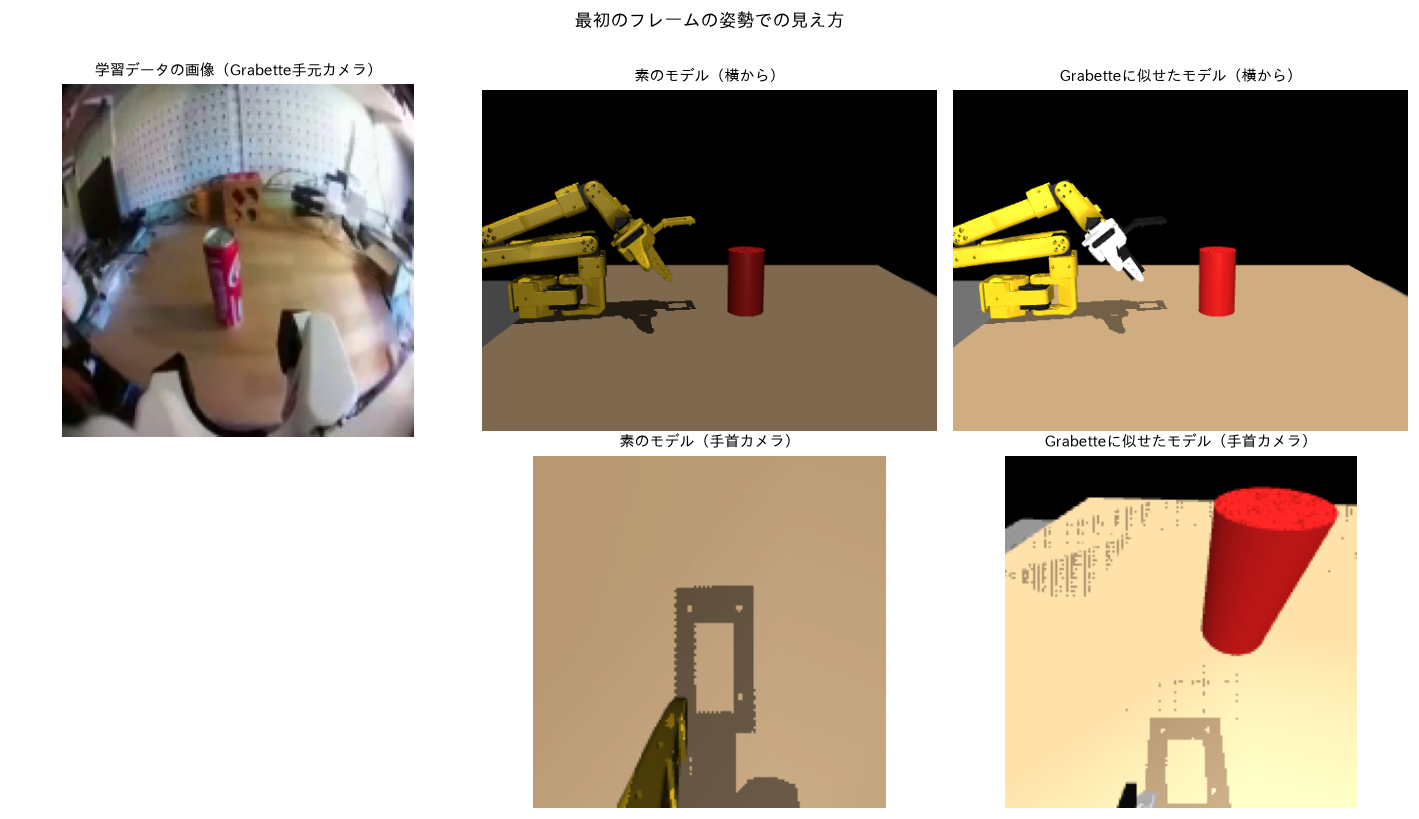

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.4))
axes[0, 0].imshow(demo_images[0])
axes[0, 0].set_title("学習データの画像（Grabette手元カメラ）", fontsize=10)
axes[1, 0].axis("off")
for col, (name, path) in enumerate(SCENES.items(), start=1):
    sim = CanSim(path, demo_joints[0])
    axes[0, col].imshow(sim.side_view())
    axes[0, col].set_title(f"{name}（横から）", fontsize=10)
    axes[1, col].imshow(sim.wrist_image())
    axes[1, col].set_title(f"{name}（手首カメラ）", fontsize=10)
    sim.close()
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("最初のフレームの姿勢での見え方", y=1.0)
plt.tight_layout()
plt.savefig(OUT_DIR / "06_patterns.png", bbox_inches="tight")
plt.show()

- 素のモデルの手首カメラは横を向いており、テーブル面と自分のグリッパーの一部しか写らない。
- Grabetteに似せたモデルの手首カメラには、缶とテーブルが写る。
- どちらの画像も、学習データの画像（実写・魚眼レンズ・物の多い実験室の背景・画面下部の白い指）とは大きく異なる。

## 2. 参考: 学習データの動作をそのまま再生する

方策を動かす前に、この環境で缶を持ち上げられること自体を確かめる。
学習データのエピソード10の関節角を、そのまま目標として1フレームずつ与える。

In [9]:
def run(scene_path, controller, n_steps, label):
    """
    シミュレーションをn_stepsステップ動かし、記録と動画のフレームを返す。

    controllerは、次の2つの働きを持つ。
      controller.plan(sim, t)    : ステップtからの数ステップ分の目標関節角の並びを返す
      controller.observe(sim, t) : ステップt（tステップ実行した後）の観測を記録する
    返された目標を順に実行し、尽きたら再びplanを呼ぶ。
    """
    sim = CanSim(scene_path, demo_joints[0])
    controller.observe(sim, 0)
    record = {"joints": [], "lift": [], "contact": []}
    frames = []
    t = 0
    while t < n_steps:
        for target in controller.plan(sim, t):
            if t >= n_steps:
                break
            sim.step(np.clip(target, -3.0, 3.0))
            controller.observe(sim, t + 1)
            record["joints"].append(sim.joints())
            record["lift"].append(sim.can_lift_mm())
            record["contact"].append(sim.jaw_contact())
            if t % 2 == 0:              # 動画は2ステップおき（15 fps）
                view = sim.side_view()
                inset = cv2.resize(sim.wrist_image(), (140, 140))
                view[-144:-4, -144:-4] = inset          # 右下に手首カメラ
                touching = "yes" if record["contact"][-1] else "no"
                text = (f"{label}  t={t}  lift={record['lift'][-1]:+.1f}mm"
                        f"  contact={touching}")
                cv2.putText(view, text, (8, 22), cv2.FONT_HERSHEY_SIMPLEX,
                            0.5, (255, 255, 255), 1, cv2.LINE_AA)
                frames.append(view)
            t += 1
    sim.close()
    record = {k: np.array(v) for k, v in record.items()}
    return record, frames


class ReplayController:
    """学習データの関節角を1フレームずつ返す（観測は使わない）。"""

    def plan(self, sim, t):
        return [demo_joints[t]]

    def observe(self, sim, t):
        pass


results = {}
for name, path in SCENES.items():
    record, frames = run(path, ReplayController(), len(demo_joints),
                         "REPLAY")
    results[("学習データの再生", name)] = record
    video = save_mp4(frames, SIM_DIR / f"replay_{path.stem}.mp4", fps=15)
    print(f"{name}: 缶の最大上昇量{record['lift'].max():.1f} mm, "
          f"グリッパーと缶の接触{record['contact'].sum()}フレーム")
show_mp4(video, width=480, title="学習データの再生（Grabetteに似せたモデル）")

素のモデル: 缶の最大上昇量44.6 mm, グリッパーと缶の接触75フレーム


Grabetteに似せたモデル: 缶の最大上昇量44.6 mm, グリッパーと缶の接触75フレーム


学習データの動作をそのまま再生すると、どちらのパターンでもグリッパーが缶を挟み、缶は4 cm以上持ち上がる。
（外観の変更は見た目だけなので、2つのパターンの物理的な結果は同じになる。）
したがって、缶の大きさ・置き場所・グリッパーの力は、把持ができる設定になっている。
**方策が学習データと同じ動作をすれば、缶を持ち上げられる** 環境である。

## 3. 方策の動かし方

05と同じ方法で学習済みモデルを読み込み、学習時と同じ定義で使う。

| 方策 | 入力 | 予測 | 実行 |
|---|---|---|---|
| DP | 直前と現在の2ステップの手首カメラ画像・関節角 | 1〜16ステップ先の関節角 | 先頭8ステップ分を実行してから、再び予測する |
| ACT | 現在の手首カメラ画像・関節角 | 現在〜15ステップ先の関節角 | 先頭8ステップ分を実行してから、再び予測する |

腕の初期姿勢は、学習データのエピソード10の最初のフレームと同じにする（学習時に見た状態から始めるため）。
動かすステップ数も、このエピソードの長さ（142ステップ）と同じにする。

In [10]:
from lerobot.policies.act.modeling_act import ACTPolicy
from lerobot.policies.diffusion.modeling_diffusion import DiffusionPolicy
from lerobot.processor import PolicyProcessorPipeline
from safetensors.torch import load_file

# ---- DP（05の3.4節と同じ読み込みと正規化）----
dp_policy = DiffusionPolicy.from_pretrained(str(DP_DIR)).to("cpu").eval()
with open(DP_DIR / "action_stats.json") as f:
    dp_stats = {k: torch.tensor(v) for k, v in json.load(f).items()
                if isinstance(v, list)}


def to_minus1_1(x, low, high):
    """最小値〜最大値を−1〜1に変換する。範囲が0の関節（wrist_roll）は0にする。"""
    span = high - low
    safe = torch.where(span < 1e-8, torch.ones_like(span), span)
    scaled = 2.0 * (x - low) / safe - 1.0
    return torch.where(span < 1e-8, torch.zeros_like(scaled), scaled)


def from_minus1_1(x, low, high):
    """−1〜1の値を、最小値〜最大値の範囲に戻す。"""
    return (x + 1.0) / 2.0 * (high - low) + low


def dp_predict(states, images, seed):
    """
    DPで1〜16ステップ先の関節角(16, 6) [rad]を予測する。

    states: 直前と現在の関節角(2, 6)、images: 同じ2ステップの画像(2, 3, H, W)
    拡散モデルは乱数から予測を作るため、乱数の初期値seedを固定して再現できるようにする。
    """
    batch = {"observation.state": to_minus1_1(states[None],
                                              dp_stats["state_min"],
                                              dp_stats["state_max"]),
             "observation.images": images[None, :, None]}
    with torch.no_grad():
        condition = dp_policy.diffusion._prepare_global_conditioning(batch)
        predicted = dp_policy.diffusion.conditional_sample(
            1, global_cond=condition,
            generator=torch.Generator().manual_seed(seed))
    return from_minus1_1(predicted[0], dp_stats["action_min"],
                         dp_stats["action_max"]).numpy()


# ---- ACT（05の4.4節と同じ読み込みと正規化）----
act_policy = ACTPolicy.from_pretrained(str(ACT_DIR)).to("cpu").eval()
act_pre = PolicyProcessorPipeline.from_pretrained(
    str(ACT_DIR), config_filename="policy_preprocessor.json",
    overrides={"device_processor": {"device": "cpu"}})
UNNORMALIZER = "policy_postprocessor_step_0_unnormalizer_processor.safetensors"
act_stats = load_file(str(ACT_DIR / UNNORMALIZER))


def act_predict(state, image):
    """ACTで現在〜15ステップ先の関節角(16, 6) [rad]を予測する。"""
    with torch.no_grad():
        batch = act_pre({"observation.state": state[None],
                         "observation.images.front": image[None]})
        predicted = act_policy.predict_action_chunk(batch)[0]
    return (predicted * act_stats["action.std"]
            + act_stats["action.mean"]).numpy()


def to_tensor(image):
    """画像(H, W, 3)の0〜255の値を、学習時と同じ(3, H, W)の0〜1に直す。"""
    return torch.tensor(image, dtype=torch.float32).permute(2, 0, 1) / 255.0

Loading weights from local directory


Loading weights from local directory


In [11]:
class PolicyController:
    """
    学習済み方策で目標の関節角を作る。

    image_source="sim"  : シミュレーションの手首カメラ画像を入力する（通常の動作）
    image_source="demo" : 画像だけを学習データのその時刻の画像に差し替える（6節の診断用）
    """

    def __init__(self, policy, image_source="sim"):
        self.policy = policy
        self.image_source = image_source
        self.history = []        # 各ステップの観測 (関節角, 画像) の記録

    def observe(self, sim, t):
        """tステップ実行した後の関節角と画像を記録する。"""
        if self.image_source == "demo":
            image = demo_images[min(t, len(demo_images) - 1)]
        else:
            image = sim.wrist_image()
        self.history.append((torch.tensor(sim.joints(), dtype=torch.float32),
                             to_tensor(image)))

    def plan(self, sim, t):
        """現在（と直前）の観測から予測し、先頭8ステップ分を返す。"""
        state, image = self.history[-1]
        if self.policy == "DP":
            # 直前のステップの観測（最初のステップでは現在と同じものを使う）
            previous = self.history[-2] if len(self.history) > 1 else (
                state, image)
            chunk = dp_predict(torch.stack([previous[0], state]),
                               torch.stack([previous[1], image]), seed=t)
        else:
            chunk = act_predict(state, image)
        return chunk[:8]


def run_policy(policy, scene_name, image_source="sim"):
    label = f"{policy} {'DEMO-IMAGE' if image_source == 'demo' else 'SIM'}"
    record, frames = run(SCENES[scene_name],
                         PolicyController(policy, image_source),
                         len(demo_joints), label)
    tag = f"{policy}_{SCENES[scene_name].stem}_{image_source}"
    video = save_mp4(frames, SIM_DIR / f"{tag}.mp4", fps=15)
    return record, video

観測は毎ステップ記録し、DPの「直前のステップの観測」には1ステップ前の観測を使う（学習時の「1フレーム前」と同じ）。

## 4. 結果1: 素のモデル

In [12]:
def summarize(record):
    """缶の最大上昇量・接触フレーム数・グリッパーの最小角を返す。"""
    return {"缶の最大上昇量[mm]": round(float(record["lift"].max()), 1),
            "グリッパーと缶の接触 [フレーム]": int(record["contact"].sum()),
            "グリッパーの最小角[deg]":
                round(float(np.degrees(record["joints"][:, 5].min())), 1)}


for policy in ["DP", "ACT"]:
    record, video = run_policy(policy, "素のモデル")
    results[(policy, "素のモデル")] = record
    print(policy, summarize(record))
    show_mp4(video, width=480, title=f"{policy}（素のモデル）")

DP {'缶の最大上昇量[mm]': 0.0, 'グリッパーと缶の接触 [フレーム]': 0, 'グリッパーの最小角[deg]': 0.4}


ACT {'缶の最大上昇量[mm]': 0.0, 'グリッパーと缶の接触 [フレーム]': 1, 'グリッパーの最小角[deg]': 11.1}


## 5. 結果2: Grabetteに似せたモデル

In [13]:
for policy in ["DP", "ACT"]:
    record, video = run_policy(policy, "Grabetteに似せたモデル")
    results[(policy, "Grabetteに似せたモデル")] = record
    print(policy, summarize(record))
    show_mp4(video, width=480, title=f"{policy}（Grabetteに似せたモデル）")

DP {'缶の最大上昇量[mm]': 0.0, 'グリッパーと缶の接触 [フレーム]': 0, 'グリッパーの最小角[deg]': 49.4}


ACT {'缶の最大上昇量[mm]': 0.0, 'グリッパーと缶の接触 [フレーム]': 0, 'グリッパーの最小角[deg]': 1.7}


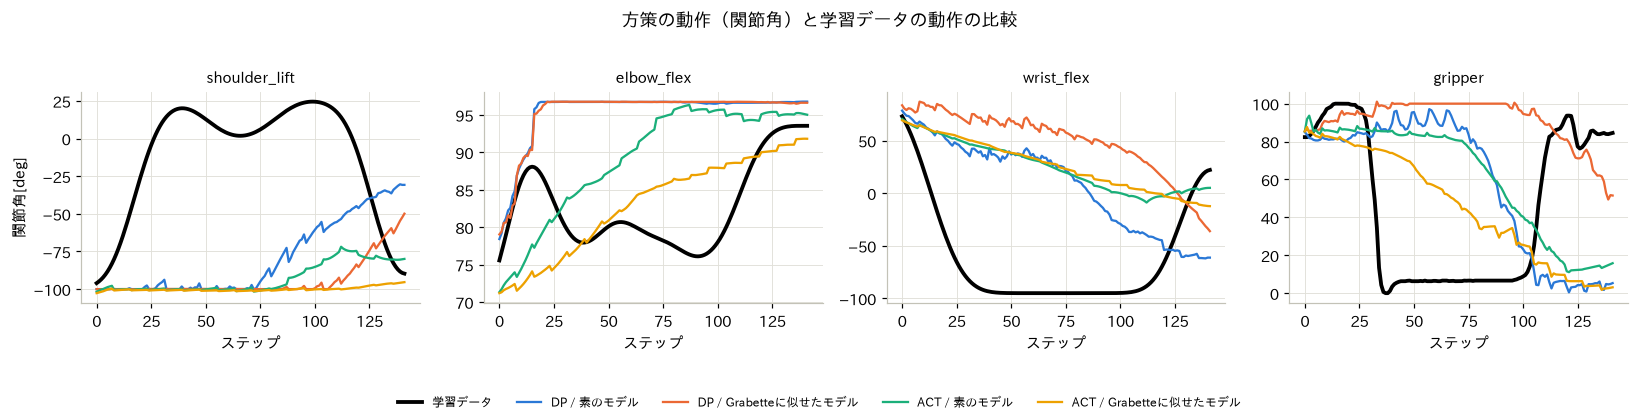

,缶の最大上昇量[mm],グリッパーと缶の接触 [フレーム],グリッパーの最小角[deg]
学習データの再生 / 素のモデル,44.6,75.0,20.7
学習データの再生 / Grabetteに似せたモデル,44.6,75.0,20.7
DP / 素のモデル,0.0,0.0,0.4
ACT / 素のモデル,0.0,1.0,11.1
DP / Grabetteに似せたモデル,0.0,0.0,49.4
ACT / Grabetteに似せたモデル,0.0,0.0,1.7


In [14]:
def plot_joint_paths(keys, title, filename):
    """各実行の関節角の時系列を、学習データの動作と重ねて描く。"""
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
    time_axis = np.arange(len(demo_joints))
    for ax, j in zip(axes, [1, 2, 3, 5]):
        ax.plot(time_axis, np.degrees(demo_joints[:, j]), color="black",
                lw=2.5, label="学習データ")
        for k, key in enumerate(keys):
            ax.plot(time_axis, np.degrees(results[key]["joints"][:, j]),
                    color=SERIES_COLORS[k], lw=1.5, label=" / ".join(key))
        ax.set_title(JOINT_NAMES[j], fontsize=10)
        ax.set_xlabel("ステップ")
    axes[0].set_ylabel("関節角[deg]")
    handles, labels = axes[0].get_legend_handles_labels()
    plt.suptitle(title, y=1.02)
    plt.tight_layout(rect=(0, 0.12, 1, 1))
    fig.legend(handles, labels, loc="lower center", ncol=len(labels),
               fontsize=8)
    plt.savefig(OUT_DIR / filename, bbox_inches="tight")
    plt.show()


plot_joint_paths([("DP", "素のモデル"), ("DP", "Grabetteに似せたモデル"),
                  ("ACT", "素のモデル"), ("ACT", "Grabetteに似せたモデル")],
                 "方策の動作（関節角）と学習データの動作の比較",
                 "06_policy_joint_paths.png")

table = pd.DataFrame({" / ".join(key): summarize(record)
                      for key, record in results.items()}).T
table

**結果のまとめ**

- 学習データの再生では缶が4 cm以上持ち上がるのに対し、方策で動かすと、どのパターンでもDP・ACTとも缶は持ち上がらない。
- 方策の関節角は、学習データの動作（黒線）から大きく外れている。
  学習データでは最初の40ステップでshoulder_liftを−95度から+20度まで上げて腕を伸ばす。
  しかし方策は、どの実行でもshoulder_liftを下限付近（約−100度, 初期姿勢のまま）に70ステップ以上とどめ、ほとんど動き出さない。
  グリッパーも、缶の無い位置でゆっくり閉じるだけである。
  学習データの「腕を伸ばす → 閉じる → 持ち上げる」という動作は再現されていない。

方策は、画像と関節角の両方を見て動作を決める。
関節角の初期値は学習データと同じなので、違いの原因は主に **画像** にあると考えられる。
これを次の診断で確かめる。

## 6. 診断: 画像だけを学習データの画像に差し替える

シミュレーション（腕・グリッパー・缶の物理）はそのままにする。
方策に入力する画像だけを、学習データのその時刻の実写画像（Grabetteの手元カメラ）に差し替えて、同じように動かす。
腕の関節角は、シミュレーションの実際の値を入力する。

DP {'缶の最大上昇量[mm]': 39.4, 'グリッパーと缶の接触 [フレーム]': 71, 'グリッパーの最小角[deg]': 20.1}
    学習データの動作との平均差[deg]（shoulder_lift, elbow_flex, wrist_flex, gripper）: [ 2.5  1.2  1.6 10.3]


ACT {'缶の最大上昇量[mm]': 5.7, 'グリッパーと缶の接触 [フレーム]': 13, 'グリッパーの最小角[deg]': -1.5}
    学習データの動作との平均差[deg]（shoulder_lift, elbow_flex, wrist_flex, gripper）: [37.6 14.7 31.1 28.9]


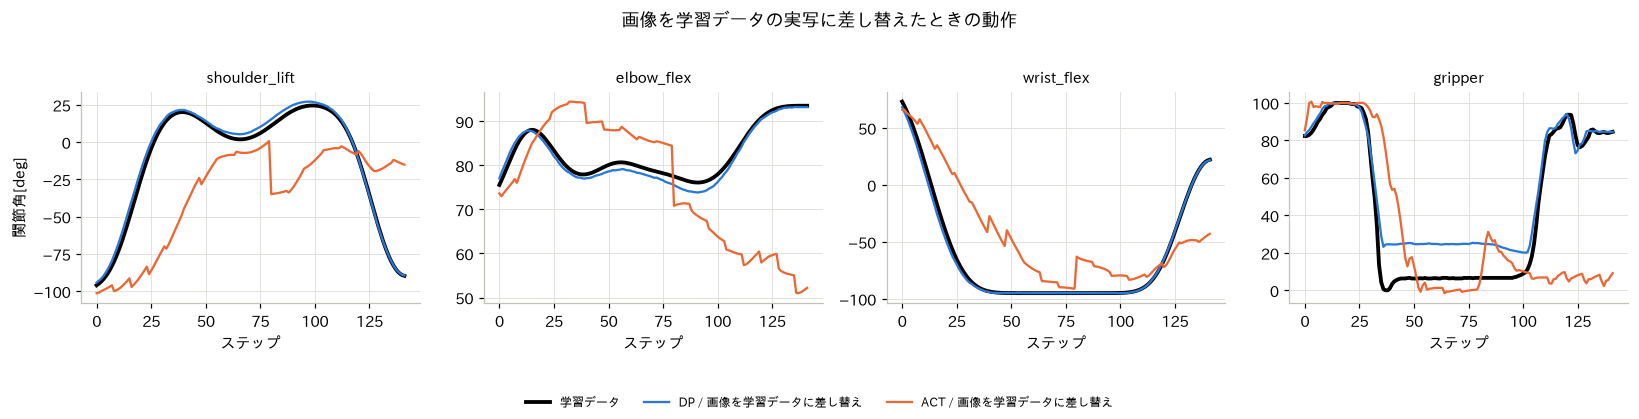

In [15]:
for policy in ["DP", "ACT"]:
    record, video = run_policy(policy, "Grabetteに似せたモデル",
                               image_source="demo")
    results[(policy, "画像を学習データに差し替え")] = record
    error = np.degrees(np.abs(record["joints"][:, [1, 2, 3, 5]]
                              - demo_joints[:, [1, 2, 3, 5]]).mean(axis=0))
    print(policy, summarize(record))
    print(f"    学習データの動作との平均差[deg]（shoulder_lift, elbow_flex, "
          f"wrist_flex, gripper）: {np.round(error, 1)}")
    show_mp4(video, width=480,
             title=f"{policy}（画像を学習データの実写に差し替え）")

plot_joint_paths([("DP", "画像を学習データに差し替え"),
                  ("ACT", "画像を学習データに差し替え")],
                 "画像を学習データの実写に差し替えたときの動作",
                 "06_diagnosis_joint_paths.png")

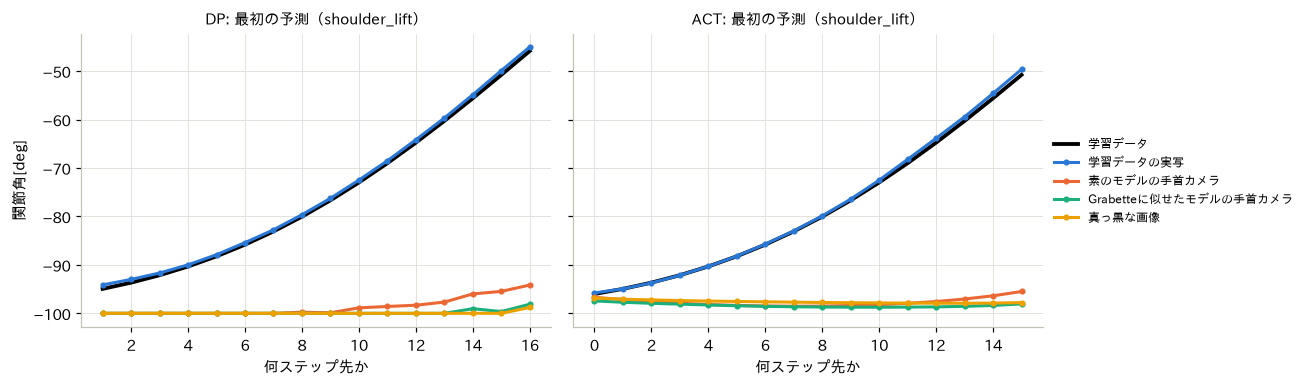

In [16]:
# 最初のステップで、入力画像だけを変えたときの予測（16ステップ分）を比べる
def first_wrist_image(scene_name):
    """最初のフレームの姿勢での手首カメラ画像を返す。"""
    sim = CanSim(SCENES[scene_name], demo_joints[0])
    image = sim.wrist_image()
    sim.close()
    return image


images = {
    "学習データの実写": demo_images[0],
    "素のモデルの手首カメラ": first_wrist_image("素のモデル"),
    "Grabetteに似せたモデルの手首カメラ":
        first_wrist_image("Grabetteに似せたモデル"),
    "真っ黒な画像": np.zeros_like(demo_images[0]),
}
state = torch.tensor(demo_joints[0], dtype=torch.float32)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, policy in zip(axes, ["DP", "ACT"]):
    steps = np.arange(1, 17) if policy == "DP" else np.arange(0, 16)
    ax.plot(steps, np.degrees(demo_joints[steps, 1]), color="black", lw=2.5,
            label="学習データ")
    for k, (name, image) in enumerate(images.items()):
        tensor = to_tensor(image)
        if policy == "DP":
            chunk = dp_predict(torch.stack([state, state]),
                               torch.stack([tensor, tensor]), seed=0)
        else:
            chunk = act_predict(state, tensor)
        ax.plot(steps, np.degrees(chunk[:, 1]), color=SERIES_COLORS[k],
                marker="o", markersize=3, label=name)
    ax.set_title(f"{policy}: 最初の予測（shoulder_lift）", fontsize=10)
    ax.set_xlabel("何ステップ先か")
axes[0].set_ylabel("関節角[deg]")
axes[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.savefig(OUT_DIR / "06_image_swap_prediction.png", bbox_inches="tight")
plt.show()

**診断の結果**

- **DP**: 画像を学習データの実写に差し替えるだけで、学習データとほぼ同じ動作になり、缶を持ち上げた。
  シミュレーションの物理も関節角の入力も同じなので、シミュレーション画像のときに失敗した主な原因は **画像の違い** である。
- **ACT**: 実写に差し替えると、学習データと同じ形の動作（腕を伸ばす → 閉じる → 持ち上げる）を行う。
  ただし動きが学習データより遅く、遅れが積み重なるため、缶の位置でグリッパーを閉じる時刻がずれる。
  その結果、持ち上げには至らない（7節の理由5）。
- 最初の予測を比べると、同じ関節角でも、入力画像によって予測される動作が大きく変わる。
  学習データの実写を入れると、DP・ACTとも学習データとほぼ同じ「腕を上げ始める」予測になる。
  シミュレーション画像（どちらのパターンも）を入れると、真っ黒な画像を入れた場合と同じく、shoulder_liftを約−100度に保つ「その場にとどまる」予測になる。
  つまり方策にとって、シミュレーション画像は「動き出すべき場面」を示す手がかりを含まない画像であり、真っ黒な画像と同程度の情報しか持たない。
- DPを実写で動かしたとき、グリッパーは約25度で止まり、学習データ（約6度）まで閉じない。
  これは缶（直径49.5 mm）に当たって閉じきれないためであり、物理的に正しい結果である。

## 7. 考察: なぜうまくいかないのか

### 理由1（主因）: 学習時の画像とシミュレーション画像の見た目が大きく違う

方策は、Grabetteの手元カメラで撮った **実写** の画像で学習した（04の4節）。
その画像には、魚眼レンズによる歪み、物の多い実験室の背景、明るい木目のテーブル、画面下部の白い指が写っている（01の1.2節, 1.5節の図）。
シミュレーション画像は、単色の床とテーブル、影の少ない照明、歪みのない画像である。
方策は、この見た目の違いを吸収する学習（例えば、背景や色をランダムに変えた画像での学習）をしていない。
そのため、シミュレーション画像は学習時に一度も見たことのない入力になり、予測が学習データの動作から外れる。
6節の診断で、画像だけを実写に戻すとDPが缶を持ち上げたことが、この理由を直接示している。

### 理由2: 手首カメラの位置と向きがGrabetteと違う

- **素のモデル**: mujoco_menagerieの手首カメラは横を向いている（04の3.2節）。缶そのものが写らない。
- **Grabetteに似せたモデル**: 向きをグリッパーの先に直したので缶は写る。
  しかし、カメラとジョーの位置関係・視野の広さ・レンズの歪みはGrabetteと同じではない。
  Grabetteの画像では2本の指が画面の下の左右に大きく写るが、シミュレーションではそのようには写らない（1.5節の図）。

外観をGrabetteに似せる（パターン2）だけでは、画像の違いは埋まらない。

### 理由3: リターゲットでは手首の向きを合わせていない

02のIKは、SO-101の腕が5関節しかないため、**先端の位置だけを合わせ、向きはほとんど合わせていない**（姿勢の重み1e-4）。
さらにwrist_rollは−90度に固定した（02の3.2節）。
そのため、変換後のSO-101の手首カメラが向く方向は、同じ時刻のGrabetteのカメラの向きとは一致しない
（例: 初期姿勢ではグリッパーは下を向くが、Grabetteは前を向いて構えている。02の3.1節）。
したがって、シミュレーションの描画を実写とまったく同じにできたとしても、方策に入る画像は学習時の画像と同じにはならない。
学習データは「Grabetteのカメラの画像」と「SO-101の関節角」の組であり、SO-101自身のカメラで撮った画像の組ではない。

### 理由4: 大きさの縮小（0.75倍）と画像の関係

03で人の動作を0.75倍に縮め、本ノートブックでは缶も0.75倍にした。
しかし学習時の画像は、縮小していない実物の缶と実際の距離で撮られている。
SO-101の手首カメラから見た缶の大きさや距離感は、学習時の画像とは一致しない。

### 理由5（ACT）: 動作の遅れが積み重なる

ACTは、画像を実写に差し替えても学習データより動きが遅く、遅れが積み重なった。
05では、学習データから選んだサンプルでの1回の予測の誤差は1度未満だった。
しかし実際に動かすと、予測 → 実行 → 次の予測 と繰り返すうちに、学習データにない状態へずれていく。
さらに6節の診断では、画像は学習データの時刻どおりに進むが、腕の状態は遅れている。
画像と関節角の組が学習時の組み合わせとずれていくため、遅れが回復しにくい。
なおACTは、予測の先頭（現在の時刻のaction）が現在の関節角そのものになるように学習している。
04でactionとobservation.stateを同じ値で保存したためで、この定義も「その場にとどまる」予測を促しうる。
どの要因がどれだけ効いているかの切り分けは、今後の課題である。

### 理由6: 評価は学習データの範囲でしか行っていない

05の予測誤差は学習データに対する値であり、新しい場面への強さ（汎化性能）は確かめていない。
本ノートブックのシミュレーションは、画像の面では学習データとまったく違う「新しい場面」であり、汎化性能が直接問われる条件である。

### 補足: 時間の進み方について

04で、元の50 fpsのデータを30 fpsとして記録した。
シミュレーションでも1ステップ = 1フレームとして動かしたので、学習時とシミュレーションの間では時間の定義は揃っている。
ただし実機で動かす場合は、人の実演より1.67倍ゆっくりした動作になる点に注意が必要である。

### 改善の方向

| 理由 | 対策の例 |
|---|---|
| 1. 見た目の違い | シミュレーション画像の背景・照明・色をランダムに変えた画像を学習に加える。魚眼レンズの歪みを描画で再現する |
| 2. カメラの位置・向き | SO-101に、Grabetteと同じ位置・向き・レンズのカメラを取り付ける（シミュレーションと実機の両方） |
| 3. 手首の向き | 画像を入力にする方策では、手首の向きも合わせるリターゲット（姿勢の重みを大きくする、6関節の腕を使う）を検討する |
| 4. 大きさ | 縮小率と、カメラから見た物体の大きさが矛盾しない設定（縮小しない、または画像側も対応させる）を検討する |
| 5. ACTの遅れ | actionを「次のフレームの関節角」として保存し直す。予測を重ね合わせる時間的アンサンブルを使う |
| 6. 評価 | 学習に使っていないエピソードやシミュレーション画像で評価する |

## まとめ

| 実行 | 缶の持ち上げ |
|---|---|
| 学習データの再生（両パターン） | 成功（4 cm以上） |
| DP・ACT（素のモデル） | 失敗 |
| DP・ACT（Grabetteに似せたモデル） | 失敗 |
| DP（画像だけ学習データの実写に差し替え） | 成功 |
| ACT（画像だけ学習データの実写に差し替え） | 失敗（動作は似るが遅れる） |

学習済みの方策は、学習時と同じ種類の画像（Grabetteの実写）が入力されれば、DPについては缶を持ち上げる動作を再現できる。
しかしシミュレーションのSO-101の手首カメラ画像では、外観をGrabetteに似せても動作しない。
主な原因は画像の違い（理由1・2）である。
加えて、リターゲットが手首の向きを合わせていないため、正しく描画できたとしても学習時の画像は再現されない（理由3）。